# Big Data Analytics for Energy Consumption Prediction
***
**Course Project / Mentor Presentation**  
*Goal: Predict future household energy demand levels (Low, Medium, High) using scalable Big Data frameworks (Pandas vs. PySpark) and Supervised Machine Learning Classifier Models.*

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn shap tables joblib pyspark

In [ ]:
import os
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import shap
import joblib

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)
print("Libraries imported successfully.")

Pandas: 2.2.3
Scikit-learn: 1.6.1
SHAP: 0.54.1
Libraries imported successfully.


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Energy_ML_Project"
)

MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"
PLOT_DIR = RESULT_DIR / "plots"

for folder in [MODEL_DIR, RESULT_DIR, PLOT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/Energy_ML_Project


In [ ]:
#loading my dataset

df = pd.read_csv("/content/drive/MyDrive/Energy_ML_Project/Dataset/household_power_consumption.csv")
display(df.head())

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16-12-2006,17:24:00,4.216,0.418,234.84,18.4,0,1,17.0
1,16-12-2006,17:25:00,5.36,0.436,233.63,23,0,1,16.0
2,16-12-2006,17:26:00,5.374,0.498,233.29,23,0,2,17.0
3,16-12-2006,17:27:00,5.388,0.502,233.74,23,0,1,17.0
4,16-12-2006,17:28:00,3.666,0.528,235.68,15.8,0,1,17.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Date                   1048575 non-null  object 
 1   Time                   1048575 non-null  object 
 2   Global_active_power    1048575 non-null  object 
 3   Global_reactive_power  1048575 non-null  object 
 4   Voltage                1048575 non-null  object 
 5   Global_intensity       1048575 non-null  object 
 6   Sub_metering_1         1048575 non-null  object 
 7   Sub_metering_2         1048575 non-null  object 
 8   Sub_metering_3         1044506 non-null  float64
dtypes: float64(1), object(8)
memory usage: 72.0+ MB


In [ ]:
# Shape of the dataset
print("Rows and columns:", df.shape)


Rows and columns: (1048575, 9)


In [ ]:
# list of columns in my dataset
print(df.columns.tolist())


['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


In [ ]:
df['dateTime'] = df['Date'] + ' '+ df['Time']
df['dateTime']

,dateTime
0,16-12-2006 17:24:00
1,16-12-2006 17:25:00
2,16-12-2006 17:26:00
3,16-12-2006 17:27:00
4,16-12-2006 17:28:00
...,...
1048570,13-12-2008 21:34:00
1048571,13-12-2008 21:35:00
1048572,13-12-2008 21:36:00
1048573,13-12-2008 21:37:00


In [ ]:
df['dateTime'][0]
format_code = '%d-%m-%Y %H:%M:%S'
df['dateTime'] = pd.to_datetime(df['dateTime'], format=format_code)

In [ ]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,dateTime
0,16-12-2006,17:24:00,4.216,0.418,234.84,18.4,0,1,17.0,2006-12-16 17:24:00
1,16-12-2006,17:25:00,5.36,0.436,233.63,23,0,1,16.0,2006-12-16 17:25:00
2,16-12-2006,17:26:00,5.374,0.498,233.29,23,0,2,17.0,2006-12-16 17:26:00
3,16-12-2006,17:27:00,5.388,0.502,233.74,23,0,1,17.0,2006-12-16 17:27:00
4,16-12-2006,17:28:00,3.666,0.528,235.68,15.8,0,1,17.0,2006-12-16 17:28:00


In [ ]:
#marking dateTime as index
#and removing Date,Time,dateTime columns

df.set_index(df['dateTime'],inplace=True)
df.drop(columns=['Date','Time','dateTime'],inplace = True)


In [ ]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
dateTime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0,1,17.0
2006-12-16 17:25:00,5.36,0.436,233.63,23,0,1,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23,0,2,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23,0,1,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0,1,17.0


In [ ]:
# handiling the missing values
df.isna().sum()

,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,4069


In [ ]:
#identifing the missing value it range from 0.1 - 1.0
#0.99 means we can drop the missing records
#0.75 means filling missing values using the surrounding data points
#0.1 means drop the entire column cause most of the data is missing in the column


(len(df) - len(df.loc[df['Sub_metering_3'].isna()]))/len(df)


0.9961194955058055

In [ ]:
len(df) , len(df.loc[df['Sub_metering_3'].isna()])
##  we can drop null valuse that is not effect as
df.dropna(how='any',axis=0,inplace=True)

In [ ]:
df.isna().sum()


,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [ ]:
#converting object type data into float32

columns = df.select_dtypes(include='object').columns
for col in columns:
    df[col] = df[col].astype(np.float32)

In [ ]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1044506 entries, 2006-12-16 17:24:00 to 2008-12-13 21:38:00
Data columns (total 7 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Global_active_power    1044506 non-null  float32
 1   Global_reactive_power  1044506 non-null  float32
 2   Voltage                1044506 non-null  float32
 3   Global_intensity       1044506 non-null  float32
 4   Sub_metering_1         1044506 non-null  float32
 5   Sub_metering_2         1044506 non-null  float32
 6   Sub_metering_3         1044506 non-null  float64
dtypes: float32(6), float64(1)
memory usage: 39.8 MB


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
dateTime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.839996,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.630005,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.289993,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.740005,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.679993,15.8,0.0,1.0,17.0


In [ ]:
print("Cleaned shape:", df.shape)
print("First timestamp:", df.index.min())
print("Last timestamp:", df.index.max())
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing count"))


Cleaned shape: (1044506, 7)
First timestamp: 2006-12-16 17:24:00
Last timestamp: 2008-12-13 21:38:00

Missing values:


,Missing count
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [ ]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().T)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1044506 entries, 2006-12-16 17:24:00 to 2008-12-13 21:38:00
Data columns (total 7 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Global_active_power    1044506 non-null  float32
 1   Global_reactive_power  1044506 non-null  float32
 2   Voltage                1044506 non-null  float32
 3   Global_intensity       1044506 non-null  float32
 4   Sub_metering_1         1044506 non-null  float32
 5   Sub_metering_2         1044506 non-null  float32
 6   Sub_metering_3         1044506 non-null  float64
dtypes: float32(6), float64(1)
memory usage: 39.8 MB

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
Global_active_power,1044506.0,1.108202,1.129094,0.076000,0.288000,0.550000,1.544000,10.670000
Global_reactive_power,1044506.0,0.118273,0.109430,0.000000,0.000000,0.098000,0.186000,1.390000
Voltage,1044506.0,239.959808,3.295596,223.490005,237.970001,240.210007,242.139999,252.139999
Global_intensity,1044506.0,4.718121,4.765363,0.200000,1.200000,2.400000,6.400000,46.400002
Sub_metering_1,1044506.0,1.177451,6.308140,0.000000,0.000000,0.000000,0.000000,80.000000
Sub_metering_2,1044506.0,1.475177,6.372847,0.000000,0.000000,0.000000,1.000000,78.000000
Sub_metering_3,1044506.0,5.933837,8.210398,0.000000,0.000000,0.000000,17.000000,31.000000


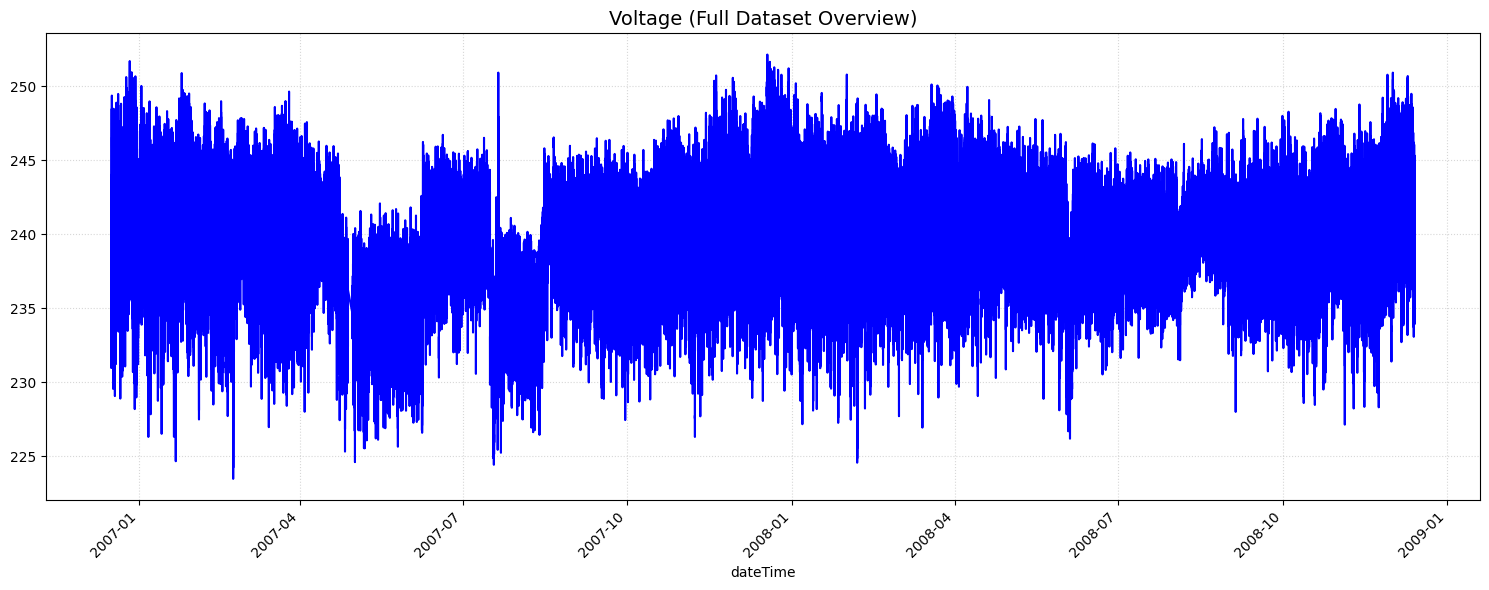

In [ ]:
# 1. Define your color palette list
color_pal = ['blue', 'red', 'green', 'orange', 'purple']

# --- PLOT 1: Full Voltage Overview ---
plt.figure(figsize=(15, 6))
df['Voltage'].plot(kind='line', color=color_pal[0])
plt.title("Voltage (Full Dataset Overview)", fontsize=14)
plt.xticks(rotation=45)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig(PLOT_DIR / "03_voltage_full_overview.png", dpi=150) # <-- SAVES TO DRIVE
plt.show()


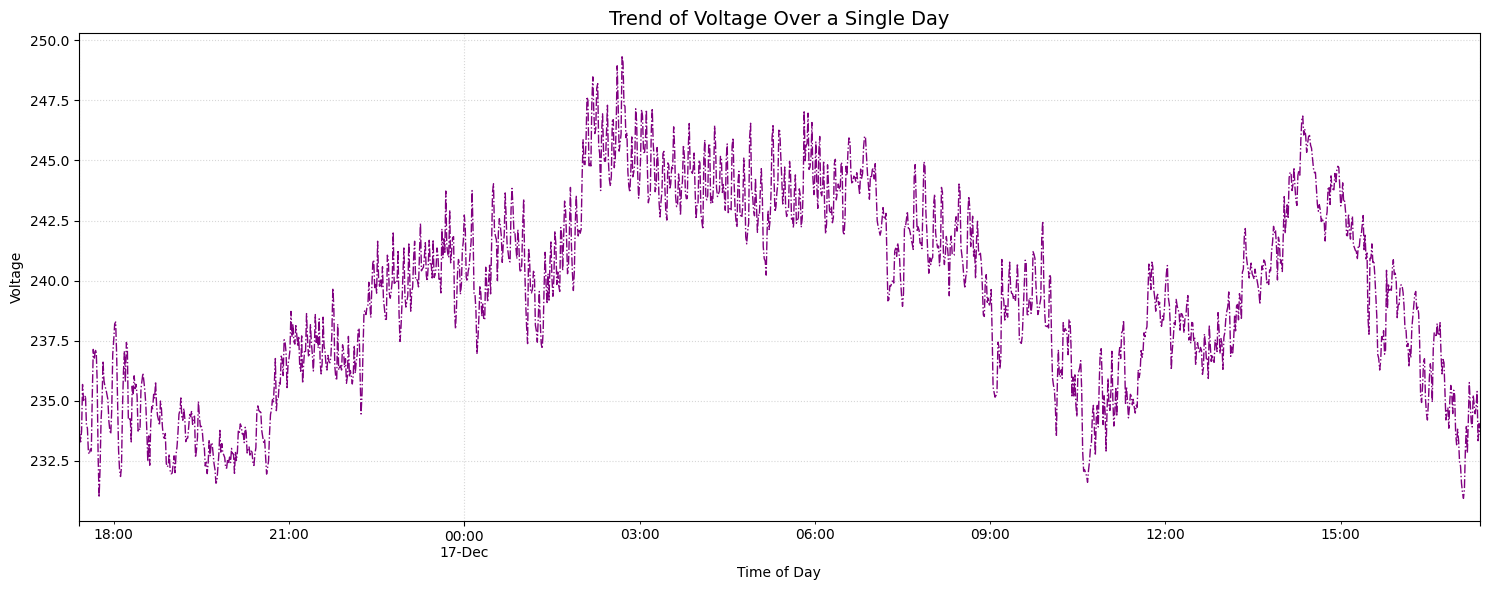

In [ ]:
day = df.loc[(df.index >= '2006-12-16 17:24:00') & (df.index < '2006-12-17 17:24:00')]

plt.figure(figsize=(15, 6))
day['Voltage'].plot(kind='line', linestyle='-.', color=color_pal[4], linewidth=1)
plt.title("Trend of Voltage Over a Single Day", fontsize=14)
plt.xlabel("Time of Day")
plt.ylabel("Voltage")
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig(PLOT_DIR / "04_voltage_day_trend.png", dpi=150) # <-- SAVES TO DRIVE
plt.show()

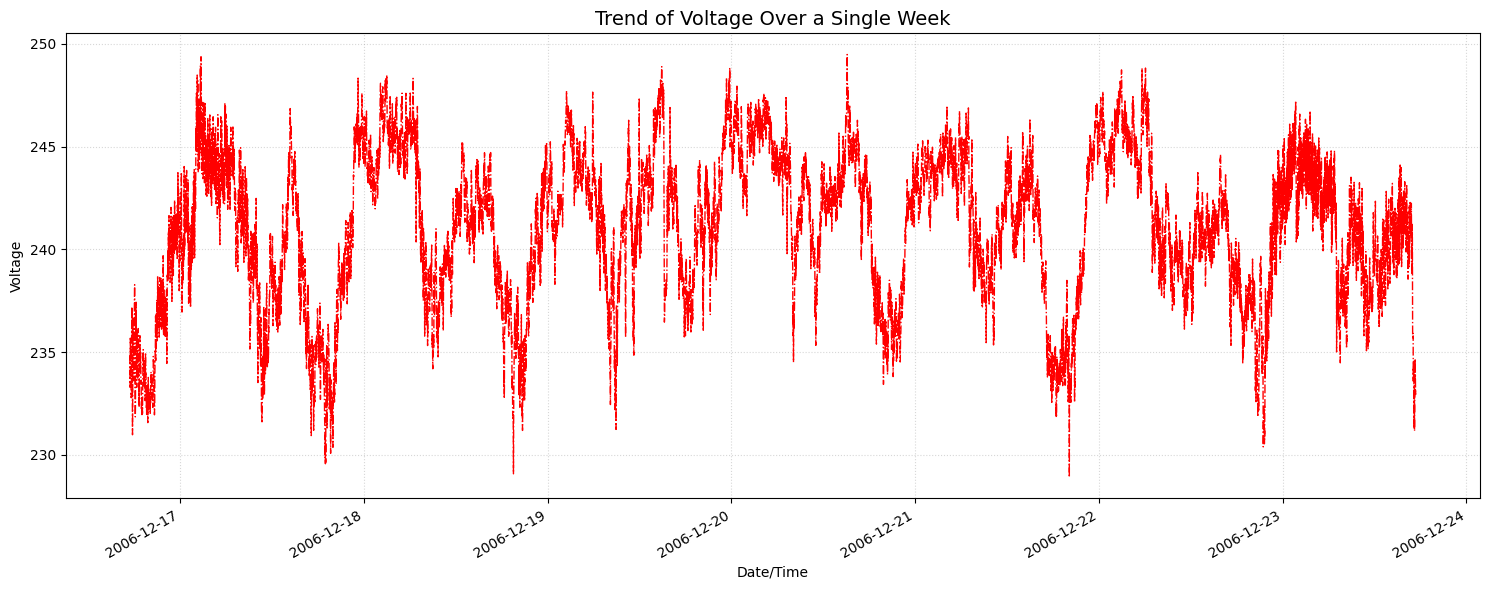

In [ ]:
# --- PLOT 3: Single Week Trend ---
week = df.loc[(df.index >= '2006-12-16 17:24:00') & (df.index < '2006-12-23 17:24:00')]

plt.figure(figsize=(15, 6))
week['Voltage'].plot(kind='line', linestyle='-.', color=color_pal[1], linewidth=1)
plt.title("Trend of Voltage Over a Single Week", fontsize=14)
plt.xlabel("Date/Time")
plt.ylabel("Voltage")
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig(PLOT_DIR / "05_voltage_week_trend.png", dpi=150) # <-- SAVES TO DRIVE
plt.show()

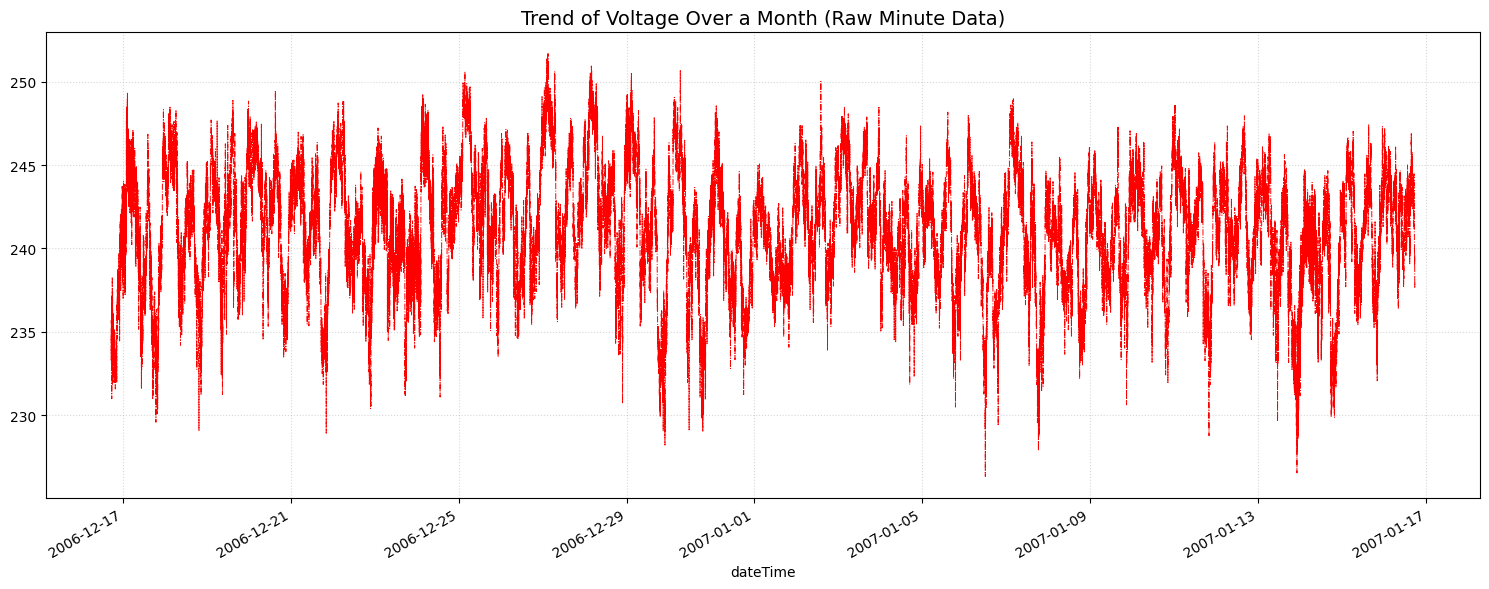

In [ ]:
# --- PLOT 4: Single Month Trend (Raw Data) ---
month = df.loc[(df.index >= '2006-12-16 17:24:00') & (df.index < '2007-01-16 17:24:00')]

plt.figure(figsize=(15, 6))
month['Voltage'].plot(kind='line', linestyle='-.', color=color_pal[1], linewidth=0.7)
plt.title("Trend of Voltage Over a Month (Raw Minute Data)", fontsize=14)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig(PLOT_DIR / "06_voltage_month_raw_trend.png", dpi=150) # <-- SAVES TO DRIVE
plt.show()

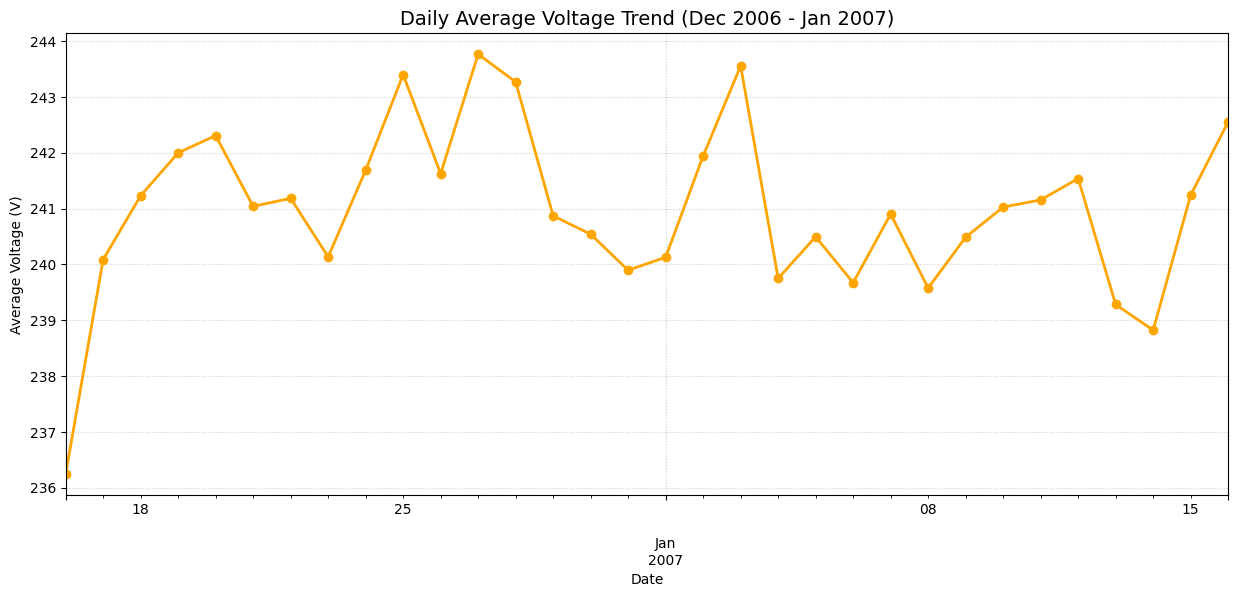

In [ ]:
# --- PLOT 5: Daily Average Month Trend (FIXED PALETTE BUG) ---
# Calculates the daily average voltage to smooth out the minute-by-minute noise
month_daily = month['Voltage'].resample('D').mean()

plt.figure(figsize=(15, 6))
month_daily.plot(kind='line', marker='o', linestyle='-', color=color_pal[3], linewidth=2) # Fixed color_pal string bug
plt.title("Daily Average Voltage Trend (Dec 2006 - Jan 2007)", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Average Voltage (V)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


In [ ]:
# Calculate the time difference between consecutive timestamps in the DataFrame index
time_difference = df.index.to_series().diff()

# Count and display the 10 most common time intervals found in the data
print("Time interval counts:")
display(time_difference.value_counts().head())

# Count and print how many intervals are exactly one minute long
print(
    "Number of one-minute intervals:",
    int((time_difference == pd.Timedelta(minutes=1)).sum())
)

# Count and print how many intervals are NOT exactly one minute long (gaps or irregular intervals)
print(
    "Number of gaps or other intervals:",
    int((time_difference != pd.Timedelta(minutes=1)).sum())
)


Time interval counts:


,count
dateTime,
0 days 00:01:00,1044466
0 days 00:02:00,20
0 days 00:03:00,10
2 days 14:04:00,1
0 days 00:04:00,1


Number of one-minute intervals: 1044466
Number of gaps or other intervals: 40


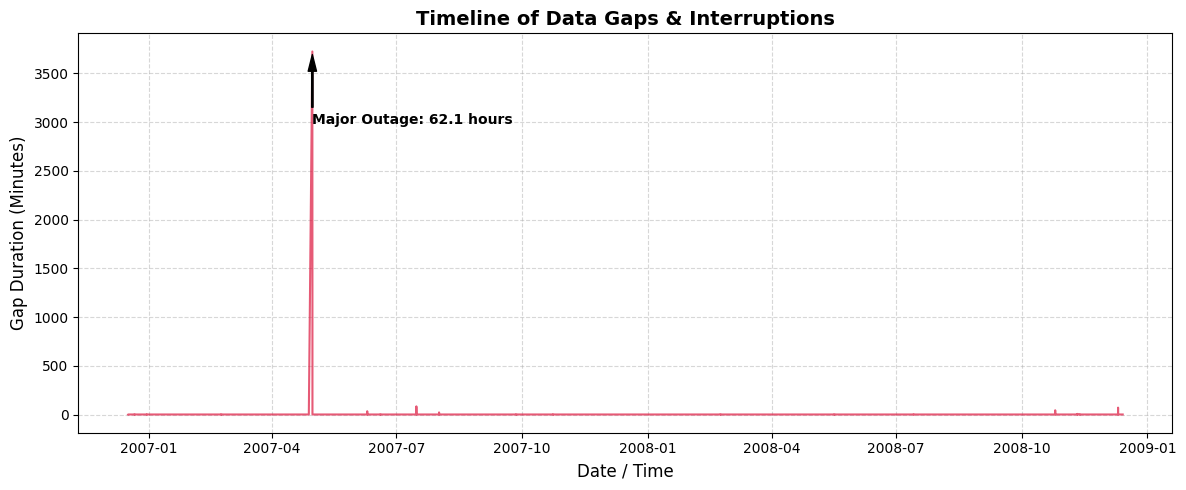

In [ ]:
# 1. Convert the time differences to minutes for easier plotting
# (We fill NaT/NaN with 0 so the first row doesn't break the plot)
gap_in_minutes = time_difference.dt.total_seconds() / 60.0
gap_in_minutes = gap_in_minutes.fillna(0)

# 2. Plot the gaps over time
plt.figure(figsize=(12, 5))
plt.plot(df.index, gap_in_minutes, color="crimson", alpha=0.7, label="Time Gap (Minutes)")

# 3. Customize the chart labels
plt.title("Timeline of Data Gaps & Interruptions", fontsize=14, fontweight="bold")
plt.xlabel("Date / Time", fontsize=12)
plt.ylabel("Gap Duration (Minutes)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)

# Highlight the huge 2-day gap dynamically
max_gap = gap_in_minutes.max()
max_gap_time = gap_in_minutes.idxmax()
if max_gap > 5:
    plt.annotate(
        f"Major Outage: {max_gap/60:.1f} hours",
        xy=(max_gap_time, max_gap),
        xytext=(max_gap_time, max_gap * 0.8),
        arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
        fontweight="bold",
        color="black",
    )

plt.tight_layout()
plt.show()


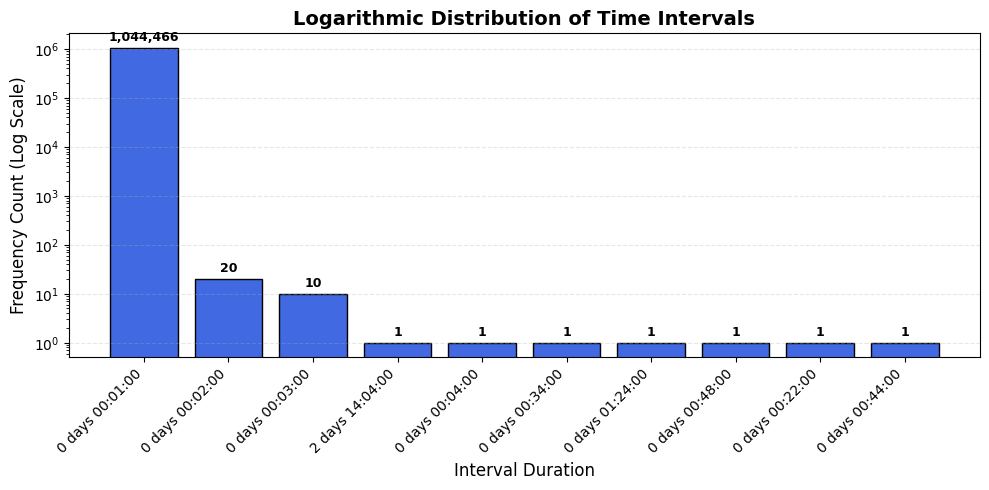

In [ ]:
# 1. Get the value counts of the gaps
counts = time_difference.value_counts().head(10)

# 2. Convert index to a string format for clean X-axis labels
x_labels = [str(interval).split(".")[0] for interval in counts.index]

# 3. Create the bar chart
plt.figure(figsize=(10, 5))
bars = plt.bar(x_labels, counts.values, color="royalblue", edgecolor="black")

# 4. Turn on Log Scale for the Y-axis so small counts (like 1 or 20) are visible next to 1,044,466
plt.yscale("log")

# 5. Add text labels on top of the bars showing the exact counts
for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval * 1.2,
        f"{int(yval):,}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

plt.title(
    "Logarithmic Distribution of Time Intervals", fontsize=14, fontweight="bold"
)
plt.xlabel("Interval Duration", fontsize=12)
plt.ylabel("Frequency Count (Log Scale)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# 1. Create a complete, unbroken timeline from the start to the end of your data
complete_timeline = pd.date_range(start=df.index.min(), end=df.index.max(), freq='1min')

# 2. Reindex the DataFrame to inject blank rows (NaN) where the gaps are
df_clean = df.reindex(complete_timeline)
df_clean.index.name = 'dateTime'

# 3. Create a flag column BEFORE filling so your model knows which rows were missing
# (True for missing rows, False for original data)
df_clean['is_imputed'] = df_clean.iloc[:, 0].isna().astype(int)

# 4. Fix short gaps (1 to 5 minutes) using linear interpolation
# Columns with text/categories will be skipped; numeric columns will be filled
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
df_clean[numeric_cols] = df_clean[numeric_cols].interpolate(method='linear', limit=5)

# 5. Drop the remaining missing rows (this removes the massive 2-day gap chunk)
# This prevents your model from training on days of purely blank or guessed data
df_clean = df_clean.dropna(subset=[col for col in df_clean.columns if col != 'is_imputed'])

print("Data repaired successfully!")
print(f"Original rows: {len(df):,}")
print(f"Cleaned rows (after minor fills & dropping the 2-day gap): {len(df_clean):,}")


Data repaired successfully!
Original rows: 1,044,506
Cleaned rows (after minor fills & dropping the 2-day gap): 1,044,589


In [ ]:
# Check if the timestamps are still perfectly 1-minute apart
current_diffs = df_clean.index.to_series().diff()
distinct_intervals = current_diffs.value_counts()

print("--- Current Dataset State ---")
print(f"Total Rows remaining: {len(df_clean):,}")
print(f"Total Missing (NaN) values: {df_clean.isna().sum().sum()}")
print("\n--- Current Time Intervals ---")
print(distinct_intervals.head(5))


--- Current Dataset State ---
Total Rows remaining: 1,044,589
Total Missing (NaN) values: 0

--- Current Time Intervals ---
dateTime
0 days 00:01:00    1044580
2 days 13:59:00          1
0 days 00:29:00          1
0 days 01:19:00          1
0 days 00:43:00          1
Name: count, dtype: int64


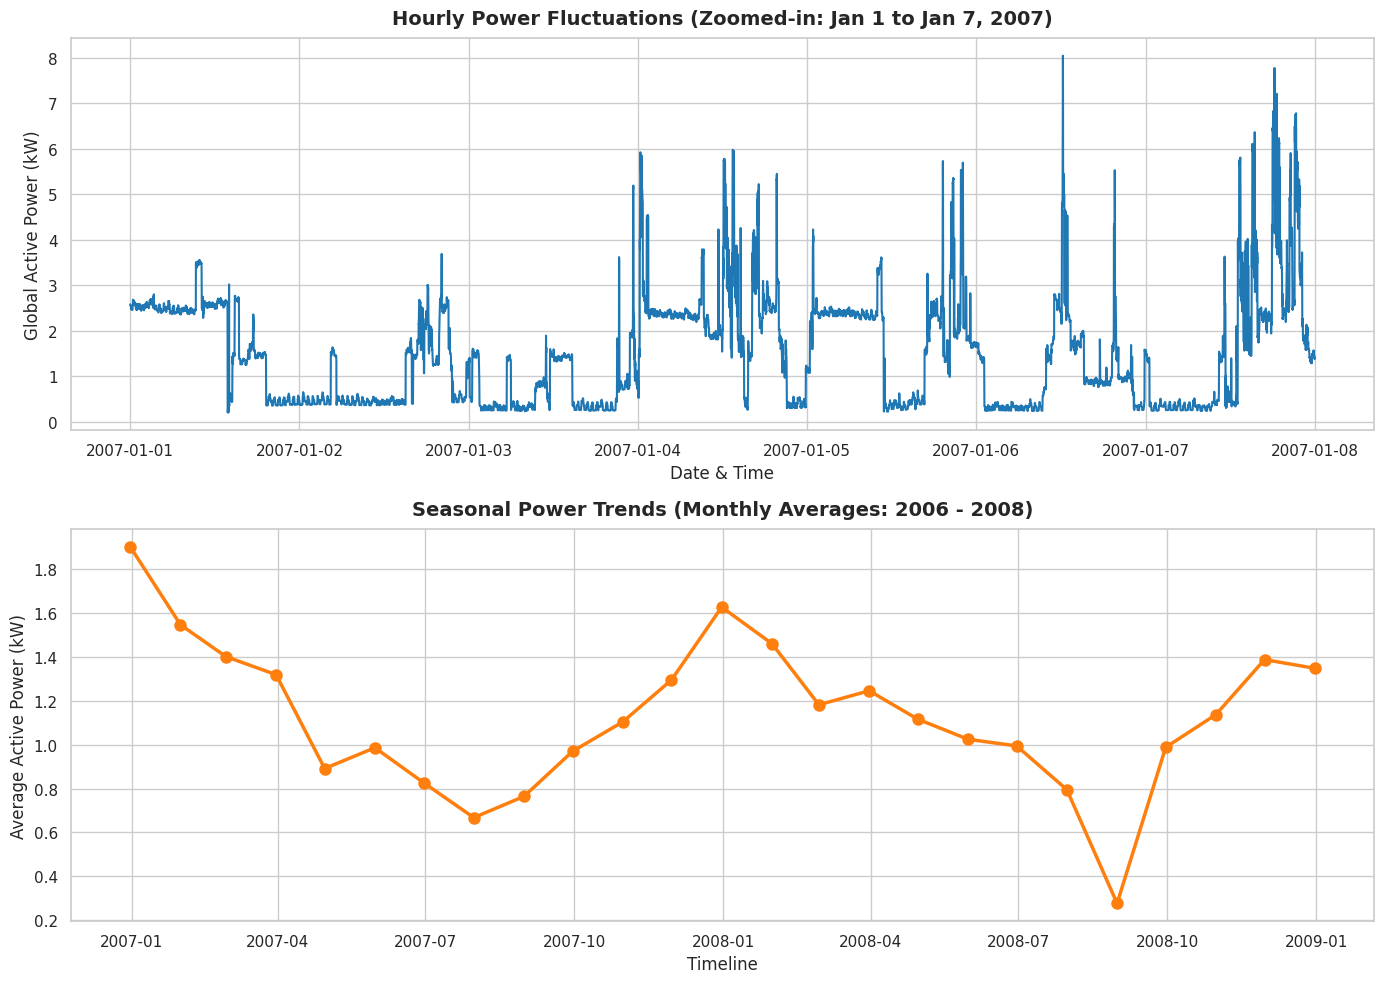

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Set style for clean, scannable aesthetics
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# --- GRAPH 1: Microscopic View (A Typical Week in January 2007) ---
# This shows daily household routines (peaks in morning/evening)
weekly_data = df_clean.loc['2007-01-01':'2007-01-07']
axes[0].plot(weekly_data.index, weekly_data['Global_active_power'], color='#1f77b4', linewidth=1.5)
axes[0].set_title('Hourly Power Fluctuations (Zoomed-in: Jan 1 to Jan 7, 2007)', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('Global Active Power (kW)', fontsize=12)
axes[0].set_xlabel('Date & Time', fontsize=12)

# --- GRAPH 2: Macroscopic View (Entire 2-Year Monthly Average) ---
# This smooths out the 1 million points to reveal long-term seasonal trends
monthly_avg = df_clean['Global_active_power'].resample('M').mean()
axes[1].plot(monthly_avg.index, monthly_avg.values, color='#ff7f0e', marker='o', linewidth=2.5, markersize=8)
axes[1].set_title('Seasonal Power Trends (Monthly Averages: 2006 - 2008)', fontsize=14, fontweight='bold', pad=10)
axes[1].set_ylabel('Average Active Power (kW)', fontsize=12)
axes[1].set_xlabel('Timeline', fontsize=12)

plt.tight_layout()
plt.show()


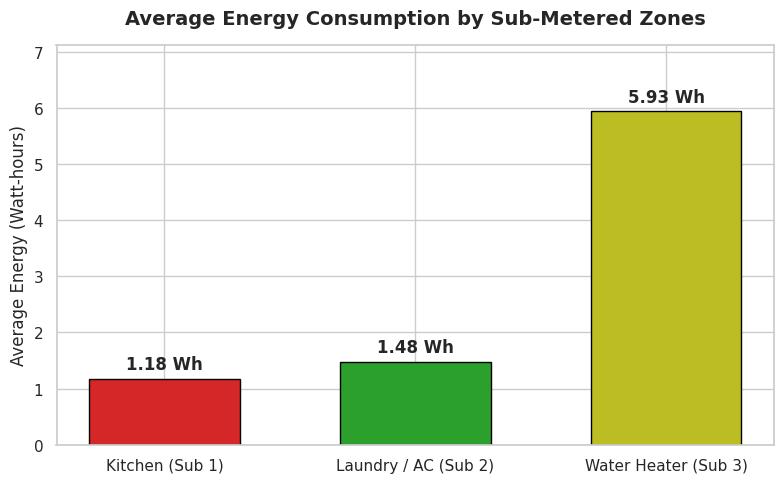

In [ ]:
# Calculate the total energy share per room
sub_metering_means = df_clean[['Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']].mean()

plt.figure(figsize=(8, 5))
colors = ['#d62728', '#2ca02c', '#bcbd22']
bars = plt.bar(sub_metering_means.index, sub_metering_means.values, color=colors, edgecolor='black', width=0.6)

# Add exact value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.1, f'{height:.2f} Wh', ha='center', va='bottom', fontweight='bold')

plt.title('Average Energy Consumption by Sub-Metered Zones', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Average Energy (Watt-hours)', fontsize=12)
plt.xticks(ticks=[0, 1, 2], labels=['Kitchen (Sub 1)', 'Laundry / AC (Sub 2)', 'Water Heater (Sub 3)'], fontsize=11)
plt.ylim(0, sub_metering_means.max() * 1.2)
plt.tight_layout()
plt.show()


In [ ]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
dateTime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.839996,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.630005,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.289993,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.740005,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.679993,15.8,0.0,1.0,17.0


In [ ]:
target_column = "Global_active_power"

measurement_features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

features_df = df.copy()

# Previous energy consumption
features_df["power_lag_1"] = (
    features_df[target_column].shift(1)
)

features_df["power_lag_5"] = (
    features_df[target_column].shift(5)
)

features_df["power_lag_15"] = (
    features_df[target_column].shift(15)
)

# Historical average; shift first to avoid including the current target
features_df["power_mean_15"] = (
    features_df[target_column]
    .shift(1)
    .rolling(window=15, min_periods=15)
    .mean()
)

# Calendar features
features_df["hour"] = features_df.index.hour
features_df["day_of_week"] = features_df.index.dayofweek

# Prediction target: active power at the next row
features_df["future_power"] = (
    features_df[target_column].shift(-1)
)

# Check that the current row is exactly one minute after
# the previous row, including the required historical window.
one_minute_gap = (
    features_df.index.to_series()
    .diff()
    .eq(pd.Timedelta(minutes=1))
)

features_df["valid_history"] = (
    one_minute_gap
    .rolling(window=15, min_periods=15)
    .sum()
    .eq(15)
)

# The next observation must also be one minute later
features_df["valid_future"] = (
    one_minute_gap.shift(-1)
    .fillna(False)
    .astype(bool)
)

features_df = features_df[
    features_df["valid_history"]
    & features_df["valid_future"]
].copy()

features_df = features_df.drop(
    columns=["valid_history", "valid_future"]
)

# A missing future target cannot be used for supervised training
features_df = features_df.dropna(
    subset=["future_power"]
)

FEATURE_COLUMNS = (
    measurement_features
    + [
        "power_lag_1",
        "power_lag_5",
        "power_lag_15",
        "power_mean_15",
        "hour",
        "day_of_week"
    ]
)

X = features_df[FEATURE_COLUMNS].copy()
y_power = features_df["future_power"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y_power.shape)
print("Number of features:", len(FEATURE_COLUMNS))
display(X.head())

Feature matrix shape: (1043888, 13)
Target shape: (1043888,)
Number of features: 13


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,power_lag_1,power_lag_5,power_lag_15,power_mean_15,hour,day_of_week
dateTime,,,,,,,,,,,,,
2006-12-16 17:39:00,3.384,0.282,237.139999,14.2,0.0,0.0,17.0,4.054,4.448,4.216,4.444133,17,5
2006-12-16 17:40:00,3.270,0.152,236.729996,13.8,0.0,0.0,17.0,3.384,5.412,5.360,4.388667,17,5
2006-12-16 17:41:00,3.430,0.156,237.059998,14.4,0.0,0.0,17.0,3.270,5.224,5.374,4.249333,17,5
2006-12-16 17:42:00,3.266,0.000,237.130005,13.8,0.0,0.0,18.0,3.430,5.268,5.388,4.119733,17,5
2006-12-16 17:43:00,3.728,0.000,235.839996,16.4,0.0,0.0,17.0,3.266,4.054,3.666,3.978267,17,5


In [ ]:
n_rows = len(X)

train_end = int(n_rows * 0.70)
validation_end = int(n_rows * 0.85)

X_train = X.iloc[:train_end].copy()
X_val = X.iloc[train_end:validation_end].copy()
X_test = X.iloc[validation_end:].copy()

power_train = y_power.iloc[:train_end].copy()
power_val = y_power.iloc[train_end:validation_end].copy()
power_test = y_power.iloc[validation_end:].copy()

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Testing rows:", len(X_test))

print("\nTime ranges:")
print("Train:", X_train.index.min(), "to", X_train.index.max())
print("Validation:", X_val.index.min(), "to", X_val.index.max())
print("Test:", X_test.index.min(), "to", X_test.index.max())

Training rows: 730721
Validation rows: 156583
Testing rows: 156584

Time ranges:
Train: 2006-12-16 17:39:00 to 2008-05-10 05:21:00
Validation: 2008-05-10 05:22:00 to 2008-08-27 00:14:00
Test: 2008-08-27 00:15:00 to 2008-12-13 21:37:00


In [ ]:
# 1. Verify that all features in X are purely numeric (no string text or objects)
print("--- Input Feature Data Types ---")
print(X_train.dtypes)

# 2. Check the distribution of your target variable to ensure it's not heavily imbalanced
print("\n--- Target Class Distribution Counts ---")
print(power_train.value_counts())

# 3. Check the target distribution in percentages
print("\n--- Target Class Distribution Percentages ---")
print(power_train.value_counts(normalize=True) * 100)


--- Input Feature Data Types ---
Global_active_power      float32
Global_reactive_power    float32
Voltage                  float32
Global_intensity         float32
Sub_metering_1           float32
Sub_metering_2           float32
Sub_metering_3           float64
power_lag_1              float32
power_lag_5              float32
power_lag_15             float32
power_mean_15            float64
hour                       int32
day_of_week                int32
dtype: object

--- Target Class Distribution Counts ---
future_power
0.218    5785
0.220    5502
0.216    5482
0.222    5356
0.224    5200
         ... 
7.076       1
8.716       1
7.976       1
7.526       1
7.650       1
Name: count, Length: 3988, dtype: int64

--- Target Class Distribution Percentages ---
future_power
0.218    0.791684
0.220    0.752955
0.216    0.750218
0.222    0.732975
0.224    0.711626
           ...   
7.076    0.000137
8.716    0.000137
7.976    0.000137
7.526    0.000137
7.650    0.000137
Name: proportion,

In [ ]:
# 1. Determine the 80th percentile threshold using ONLY the training data
power_threshold = power_train.quantile(0.80)
print(f"High Power Event Threshold: {power_threshold:.3f} kW")

# 2. Convert raw continuous values into binary classifications (True/False -> 1/0)
# Class 1 = High Power Event | Class 0 = Normal/Low Power Event
y_train = (power_train > power_threshold).astype(int)
y_val = (power_val > power_threshold).astype(int)
y_test = (power_test > power_threshold).astype(int)

# 3. Verify the new classification distributions
print("\n--- New Target Class Balance (Percentages) ---")
print(y_train.value_counts(normalize=True) * 100)


High Power Event Threshold: 1.876 kW

--- New Target Class Balance (Percentages) ---
future_power
0    80.032187
1    19.967813
Name: proportion, dtype: float64


In [ ]:
low_threshold = float(power_train.quantile(1 / 3))
high_threshold = float(power_train.quantile(2 / 3))

if high_threshold <= low_threshold:
    raise ValueError(
        "The class thresholds are equal. Inspect the target "
        "distribution and choose suitable thresholds."
    )

CLASS_NAMES = ["Low", "Medium", "High"]

def make_classes(power_values):
    return pd.cut(
        power_values,
        bins=[
            -np.inf,
            low_threshold,
            high_threshold,
            np.inf
        ],
        labels=CLASS_NAMES,
        include_lowest=True
    )

y_train = make_classes(power_train)
y_val = make_classes(power_val)
y_test = make_classes(power_test)

print(f"Low threshold: <= {low_threshold:.4f} kW")
print(
    f"Medium threshold: > {low_threshold:.4f} "
    f"and <= {high_threshold:.4f} kW"
)
print(f"High threshold: > {high_threshold:.4f} kW")

print("\nTraining class distribution:")
display(y_train.value_counts().reindex(CLASS_NAMES))

print("\nValidation class distribution:")
display(y_val.value_counts().reindex(CLASS_NAMES))

print("\nTest class distribution:")
display(y_test.value_counts().reindex(CLASS_NAMES))

Low threshold: <= 0.3360 kW
Medium threshold: > 0.3360 and <= 1.4020 kW
High threshold: > 1.4020 kW

Training class distribution:


,count
future_power,
Low,245725
Medium,241626
High,243370



Validation class distribution:


,count
future_power,
Low,75256
Medium,52280
High,29047



Test class distribution:


,count
future_power,
Low,42108
Medium,62183
High,52293


In [ ]:
# 1. High-Speed Configuration: Drop tree counts for initial benchmarking
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=50, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    ), # Reduced trees from 150 to 50 for speed
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=50, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    ), # Reduced trees from 150 to 50 for speed
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=100, learning_rate=0.1, max_leaf_nodes=31, random_state=RANDOM_STATE
    ) # Native high-speed model
}

# 2. Speed Optimization: Take a 20% random sample for training (keeps class balance intact)
# This drops training data from 730,000 to ~146,000 rows just for this fast selection step
X_train_sample = X_train.sample(frac=0.20, random_state=RANDOM_STATE)
y_train_sample = y_train.loc[X_train_sample.index]

fitted_models = {}

print("--- Starting High-Speed Training Benchmarks ---\n")

# 3. Train all models sequentially with a built-in stopwatch
for name, classifier in models.items():
    print(f"⌛ Training {name}...")
    start_time = time.time()

    # Construct individual pipeline
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    # Train using our optimized sample slice
    pipeline.fit(X_train_sample, y_train_sample)
    elapsed_time = time.time() - start_time

    # Save the fitted model
    fitted_models[name] = pipeline
    print(f"✅ {name} finished training in {elapsed_time:.2f} seconds.\n")

print("All five classifiers trained successfully!")


--- Starting High-Speed Training Benchmarks ---

⌛ Training Logistic Regression...
✅ Logistic Regression finished training in 20.04 seconds.

⌛ Training Decision Tree...
✅ Decision Tree finished training in 5.25 seconds.

⌛ Training Random Forest...
✅ Random Forest finished training in 18.80 seconds.

⌛ Training Extra Trees...
✅ Extra Trees finished training in 9.08 seconds.

⌛ Training HistGradientBoosting...
✅ HistGradientBoosting finished training in 7.31 seconds.

All five classifiers trained successfully!


In [ ]:
def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Macro Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    }

validation_results = []
training_times = {}

for name, model in fitted_models.items():
    print(f"\nTraining: {name}")

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    elapsed = time.perf_counter() - start_time
    training_times[name] = elapsed

    val_predictions = model.predict(X_val)
    metrics = calculate_metrics(y_val, val_predictions)

    metrics["Model"] = name
    metrics["Training Time (seconds)"] = elapsed

    validation_results.append(metrics)

validation_df = pd.DataFrame(validation_results)
validation_df = validation_df.sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(validation_df)

best_name = validation_df.iloc[0]["Model"]
best_model = fitted_models[best_name]

print("Best model selected using validation Macro F1:", best_name)


Training: Logistic Regression

Training: Decision Tree

Training: Random Forest

Training: Extra Trees

Training: HistGradientBoosting


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Model,Training Time (seconds)
0,0.939412,0.936544,0.935438,0.936544,0.935981,Random Forest,114.477570
1,0.938320,0.935745,0.933219,0.935745,0.934455,HistGradientBoosting,27.825425
2,0.935542,0.931077,0.931093,0.931077,0.931080,Decision Tree,12.124210
3,0.919781,0.923549,0.917786,0.923549,0.920121,Extra Trees,38.677523
4,0.902231,0.893672,0.899997,0.893672,0.894596,Logistic Regression,45.953016


Best model selected using validation Macro F1: Random Forest


In [ ]:
test_results = []
test_predictions = {}

for name, model in fitted_models.items():
    predictions = model.predict(X_test)
    test_predictions[name] = predictions

    metrics = calculate_metrics(y_test, predictions)
    metrics["Model"] = name
    metrics["Training Time (seconds)"] = training_times[name]

    test_results.append(metrics)

test_df = pd.DataFrame(test_results)
test_df = test_df.sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(test_df)

print("\nSelected model:", best_name)
print("\nClassification report for selected model:")

print(classification_report(
    y_test,
    test_predictions[best_name],
    labels=CLASS_NAMES,
    zero_division=0
))

,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Model,Training Time (seconds)
0,0.951751,0.952979,0.952366,0.952979,0.952668,Random Forest,114.477570
1,0.951425,0.952319,0.952208,0.952319,0.952263,HistGradientBoosting,27.825425
2,0.949229,0.950218,0.950169,0.950218,0.950192,Decision Tree,12.124210
3,0.942599,0.942786,0.943690,0.942786,0.943230,Extra Trees,38.677523
4,0.902206,0.911308,0.900696,0.911308,0.903802,Logistic Regression,45.953016



Selected model: Random Forest

Classification report for selected model:
              precision    recall  f1-score   support

         Low       0.95      0.96      0.95     42108
      Medium       0.94      0.94      0.94     62183
        High       0.96      0.97      0.96     52293

    accuracy                           0.95    156584
   macro avg       0.95      0.95      0.95    156584
weighted avg       0.95      0.95      0.95    156584



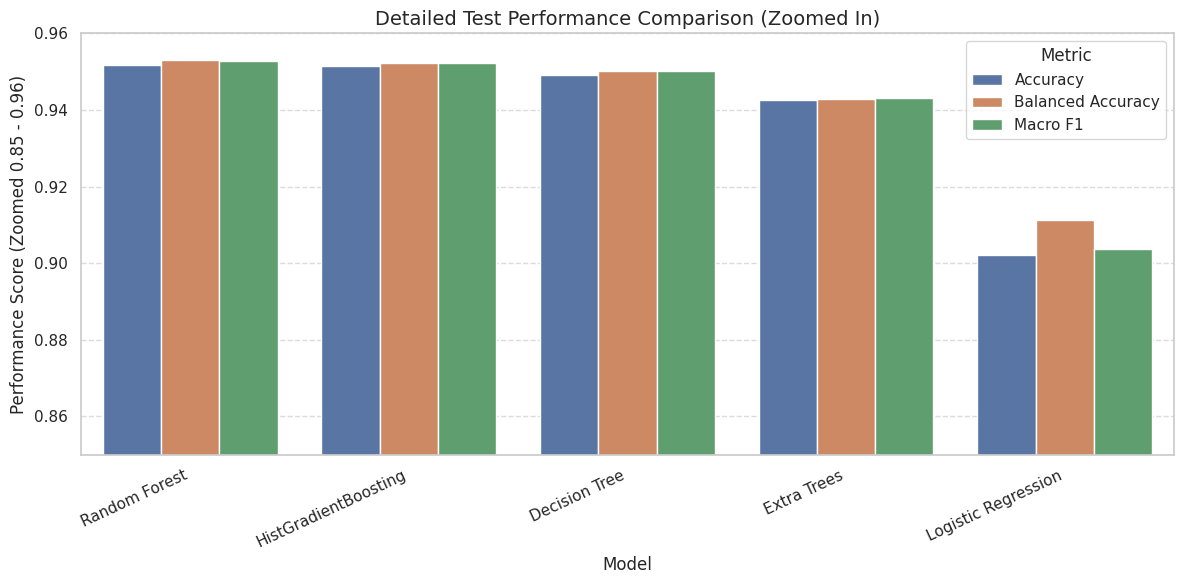

In [ ]:

# 1. Look at your dataframe columns and pick the correct name dynamically
available_columns = test_df.columns.tolist()
accuracy_col = "Accuracy (%)" if "Accuracy (%)" in available_columns else "Accuracy"

plot_source_df = test_df.copy()

# 2. Scale down if it's on a 0-100 scale
if plot_source_df[accuracy_col].max() > 1.0:
    plot_source_df[accuracy_col] = plot_source_df[accuracy_col] / 100.0

# 3. Restructure for Seaborn
plot_df = plot_source_df.melt(
    id_vars="Model",
    value_vars=[accuracy_col, "Balanced Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

# 4. Generate the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric",
    palette="deep"
)

# 5. 🔥 THE CRITICAL FIX: Zoom heavily into the 0.85 to 0.96 range!
# This cuts off the bottom 85% of the chart, forcing the differences to stand out.
plt.ylim(0.85, 0.96)

# 6. Formatting details
plt.xticks(rotation=25, ha="right")
plt.ylabel("Performance Score (Zoomed 0.85 - 0.96)")
plt.title("Detailed Test Performance Comparison (Zoomed In)", fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Save to your Google Drive
plt.savefig(PLOT_DIR / "09_model_test_zoomed_comparison.png", dpi=150)
plt.show()


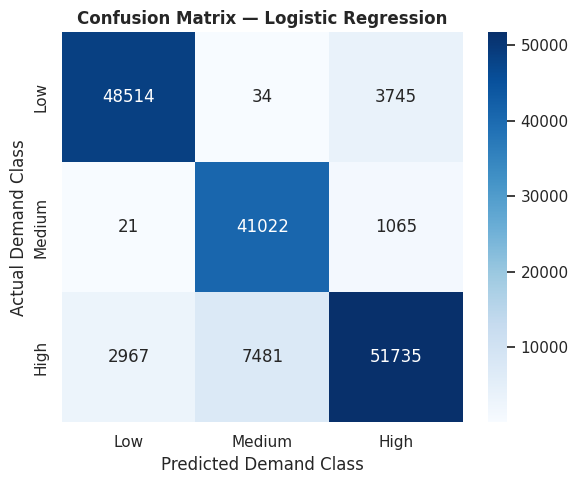

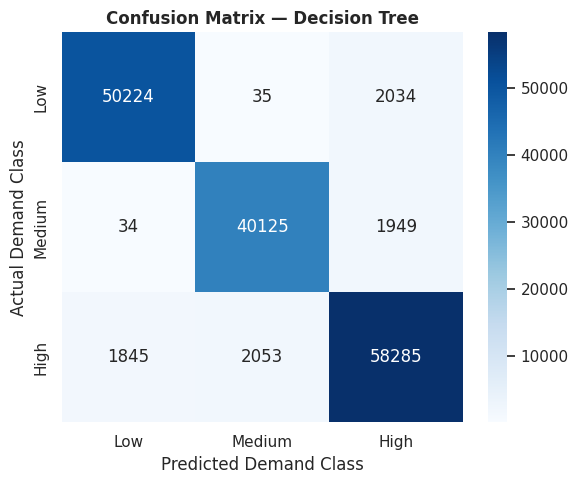

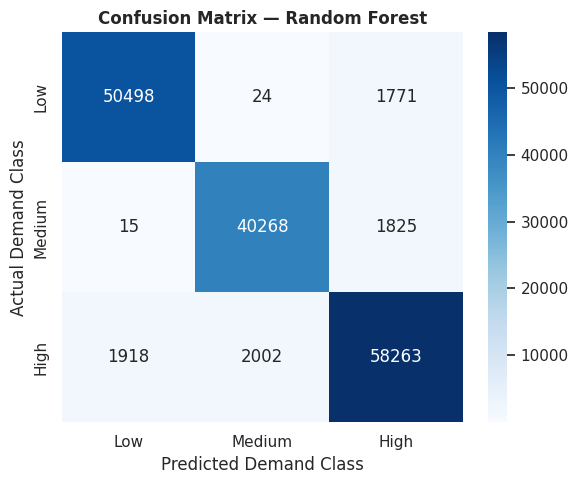

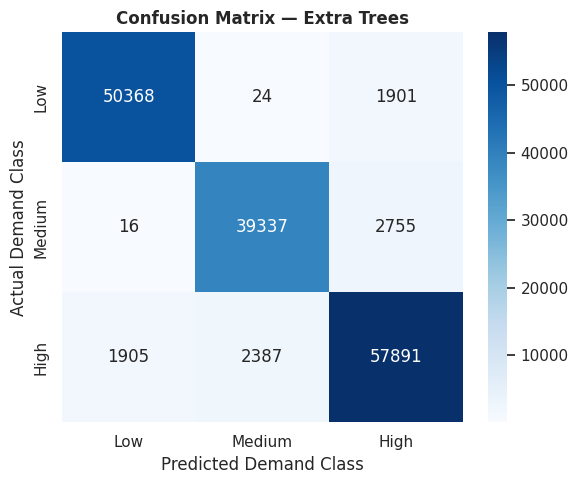

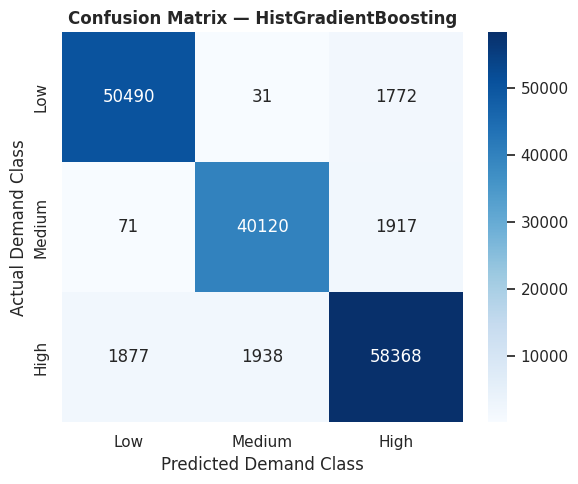

In [ ]:
# 1. Define the visual labels matching your classes exactly
CLASS_NAMES = ["Low", "Medium", "High"]

# 2. Loop through each model's saved test predictions
for name, predictions in test_predictions.items():

    # 3. CRITICAL FIX: Convert both y_test and predictions to string arrays.
    # If a model outputted '0', it cleanly becomes "0".
    # If it outputted 'Low', it stays "Low".
    y_test_str = np.array(y_test).astype(str)
    preds_str = np.array(predictions).astype(str)

    # Automatically detect what labels exist in the data to map them properly
    unique_labels = np.unique(np.concatenate([y_test_str, preds_str]))

    # 4. Generate the matrix layout completely safe from TypeErrors
    cm = confusion_matrix(
        y_test_str,
        preds_str,
        labels=unique_labels
    )

    # 5. Determine display ticks: Use custom text if count matches, otherwise fallback
    display_ticks = CLASS_NAMES if len(unique_labels) == len(CLASS_NAMES) else unique_labels

    # 6. Render the heatmap visualization
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,          # Prints the actual row counts inside the squares
        fmt="d",             # Forces numbers to display as plain integers
        cmap="Blues",        # Blue color theme
        xticklabels=display_ticks,
        yticklabels=display_ticks
    )

    plt.title(f"Confusion Matrix — {name}", fontsize=12, fontweight="bold")
    plt.xlabel("Predicted Demand Class")
    plt.ylabel("Actual Demand Class")
    plt.tight_layout()

    # 7. Save each image automatically to your permanent Google Drive folder
    safe_name = name.lower().replace(" ", "_")
    plt.savefig(
        PLOT_DIR / f"10_confusion_matrix_{safe_name}.png",
        dpi=150
    )
    plt.show()


,Feature,Importance
0,Global_active_power,0.279531
7,power_lag_1,0.222981
3,Global_intensity,0.201749
8,power_lag_5,0.097530
10,power_mean_15,0.087822
6,Sub_metering_3,0.027646
9,power_lag_15,0.027517
1,Global_reactive_power,0.016210
2,Voltage,0.012818
11,hour,0.012762


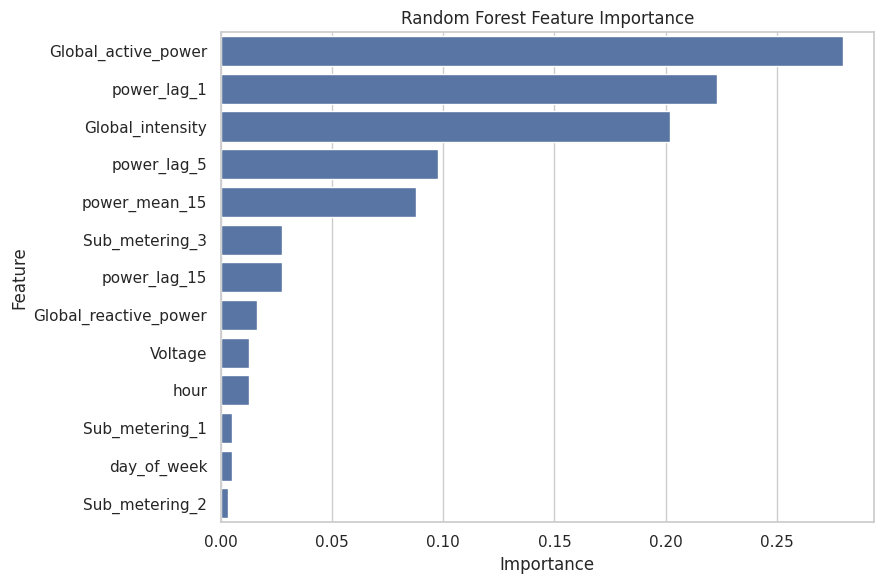

In [ ]:
rf_pipeline = fitted_models["Random Forest"]
rf_classifier = rf_pipeline.named_steps["classifier"]

rf_importance = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(rf_importance)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=rf_importance.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig(
    PLOT_DIR / "04_random_forest_feature_importance.png",
    dpi=150
)
plt.show()

,Feature,Importance Mean,Importance Std
0,Global_active_power,0.525388,0.000659
3,Global_intensity,0.138533,0.000717
7,power_lag_1,0.012831,0.000209
1,Global_reactive_power,0.006772,0.000092
4,Sub_metering_1,0.005617,0.000177
6,Sub_metering_3,0.002222,0.000117
8,power_lag_5,0.001522,0.000102
5,Sub_metering_2,0.001162,0.000104
10,power_mean_15,0.000620,0.000089
11,hour,0.000348,0.000104


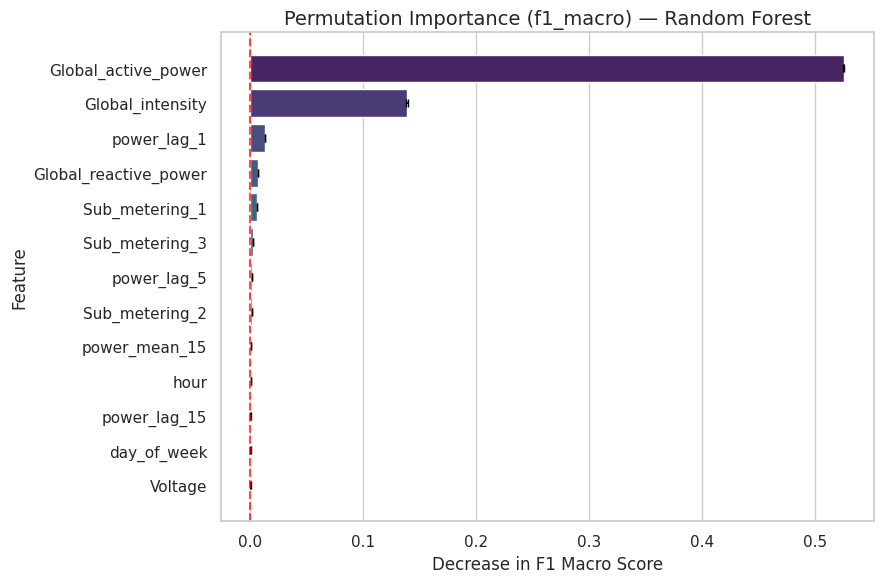

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance

# 1. Calculate Permutation Importance
permutation_result = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="f1_macro",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# 2. Build and Sort DataFrame
importance_df = pd.DataFrame(
    {
        "Feature": FEATURE_COLUMNS,
        "Importance Mean": permutation_result.importances_mean,
        "Importance Std": permutation_result.importances_std,
    }
).sort_values(by="Importance Mean", ascending=False)

# Display full results
display(importance_df)

# 3. Plot Top 15 Features
plt.figure(figsize=(9, 6))

# Using error bars to show the standard deviation (stability) of your features
sns.barplot(
    data=importance_df.head(15),
    x="Importance Mean",
    y="Feature",
    errorbar=None,  # Handled natively if passing raw arrays, or leave clean
    palette="viridis",
)

# Add error bars manually for cleaner visualization of variance
top_15 = importance_df.head(15)
plt.errorbar(
    x=top_15["Importance Mean"],
    y=top_15["Feature"],
    xerr=top_15["Importance Std"],
    fmt="none",
    c="black",
    capsize=3,
)

# Formatting
plt.title(f"Permutation Importance (f1_macro) — {best_name}", fontsize=14)
plt.xlabel("Decrease in F1 Macro Score", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.axvline(x=0, color="red", linestyle="--", alpha=0.7)  # Baseline reference

# 4. Save and Export
plt.tight_layout()
plt.savefig(PLOT_DIR / "05_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()  # Prevents memory accumulation in loops


In [ ]:
# Transform data using the preprocessing already fitted on training data
X_explain = X_test.iloc[:min(500, len(X_test))].copy()

imputer = rf_pipeline.named_steps["imputer"]
scaler = rf_pipeline.named_steps["scaler"]

X_explain_transformed = imputer.transform(X_explain)
X_explain_transformed = scaler.transform(
    X_explain_transformed
)

X_explain_transformed = pd.DataFrame(
    X_explain_transformed,
    columns=FEATURE_COLUMNS,
    index=X_explain.index
)

explainer = shap.TreeExplainer(rf_classifier)

shap_values = explainer.shap_values(
    X_explain_transformed
)

print("SHAP calculation completed.")
print("Explanation rows:", len(X_explain_transformed))
print("Explained model: Random Forest")

SHAP calculation completed.
Explanation rows: 500
Explained model: Random Forest


,Feature,Mean Absolute SHAP
0,Global_active_power,0.125329
3,Global_intensity,0.083192
7,power_lag_1,0.040606
8,power_lag_5,0.026018
10,power_mean_15,0.024774
6,Sub_metering_3,0.013528
9,power_lag_15,0.007853
11,hour,0.005051
1,Global_reactive_power,0.002503
4,Sub_metering_1,0.001830


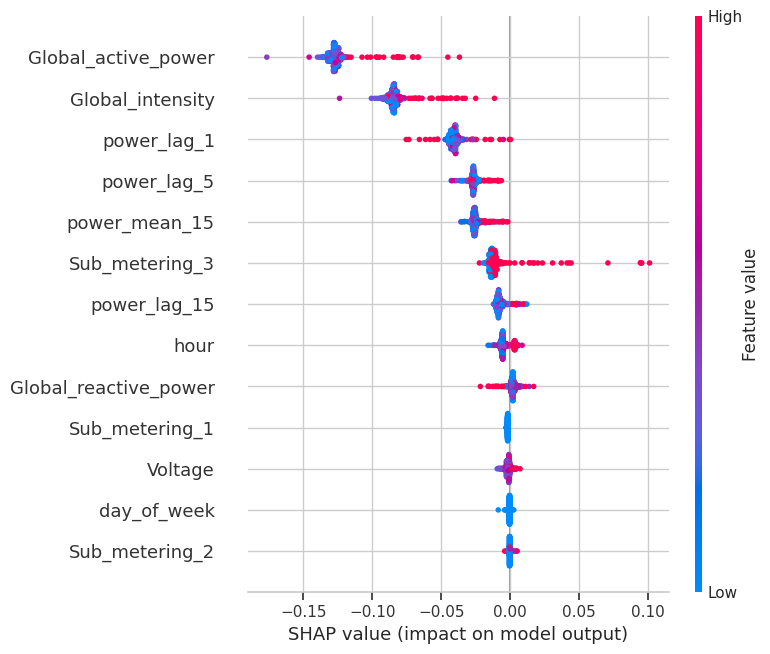

In [ ]:
class_index = list(rf_classifier.classes_).index("High")

if isinstance(shap_values, list):
    shap_high = shap_values[class_index]
else:
    shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        if shap_array.shape[-1] == len(rf_classifier.classes_):
            shap_high = shap_array[:, :, class_index]
        elif shap_array.shape[0] == len(rf_classifier.classes_):
            shap_high = shap_array[class_index]
        else:
            raise ValueError(
                f"Unexpected SHAP shape: {shap_array.shape}"
            )
    elif shap_array.ndim == 2:
        shap_high = shap_array
    else:
        raise ValueError(
            f"Unexpected SHAP dimensions: {shap_array.shape}"
        )

shap_high = np.asarray(shap_high)

if shap_high.shape != X_explain_transformed.shape:
    raise ValueError(
        f"SHAP shape {shap_high.shape} does not match "
        f"features {X_explain_transformed.shape}"
    )

shap_importance_df = pd.DataFrame({
    "Feature": FEATURE_COLUMNS,
    "Mean Absolute SHAP": np.abs(shap_high).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False)

display(shap_importance_df)

plt.figure()
shap.summary_plot(
    shap_high,
    X_explain_transformed,
    show=False
)
plt.tight_layout()
plt.savefig(
    PLOT_DIR / "06_shap_summary_high_consumption.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [ ]:
for name, model in fitted_models.items():
    safe_name = name.lower().replace(" ", "_")
    model_path = MODEL_DIR / f"{safe_name}.joblib"

    joblib.dump(model, model_path)
    print("Saved:", model_path)

print("\nSelected model:", best_name)

Saved: /content/drive/MyDrive/Energy_ML_Project/models/logistic_regression.joblib
Saved: /content/drive/MyDrive/Energy_ML_Project/models/decision_tree.joblib
Saved: /content/drive/MyDrive/Energy_ML_Project/models/random_forest.joblib
Saved: /content/drive/MyDrive/Energy_ML_Project/models/extra_trees.joblib
Saved: /content/drive/MyDrive/Energy_ML_Project/models/histgradientboosting.joblib

Selected model: Random Forest


In [ ]:
H5_PATH = RESULT_DIR / "energy_ml_results.h5"

metadata = pd.DataFrame({
    "setting": [
        "best_model",
        "target",
        "prediction_horizon",
        "low_threshold_kw",
        "high_threshold_kw",
        "train_fraction",
        "validation_fraction",
        "test_fraction",
        "random_state",
        "training_rows",
        "validation_rows",
        "test_rows"
    ],
    "value": [
        best_name,
        "Global_active_power",
        "1 minute ahead",
        low_threshold,
        high_threshold,
        0.70,
        0.15,
        0.15,
        RANDOM_STATE,
        len(X_train),
        len(X_val),
        len(X_test)
    ]
})

with pd.HDFStore(str(H5_PATH), mode="w") as store:
    store.put("validation_metrics", validation_df, format="fixed")
    store.put("test_metrics", test_df, format="fixed")
    store.put("experiment_metadata", metadata, format="fixed")
    store.put("random_forest_importance", rf_importance, format="fixed")
    store.put("permutation_importance", importance_df, format="fixed")
    store.put("shap_high_importance", shap_importance_df, format="fixed")

    shap_table = pd.DataFrame(
        shap_high,
        columns=FEATURE_COLUMNS,
        index=X_explain.index
    )
    shap_table.index.name = "datetime"
    store.put("shap_values_high", shap_table, format="fixed")

    for name, predictions in test_predictions.items():
        safe_name = name.lower().replace(" ", "_")

        output = pd.DataFrame(index=X_test.index)
        output.index.name = "datetime"
        output["actual_class"] = np.asarray(y_test).astype(str)
        output["predicted_class"] = np.asarray(predictions).astype(str)

        model = fitted_models[name]

        if hasattr(model, "predict_proba"):
            probabilities = model.predict_proba(X_test)

            for j, class_name in enumerate(model.classes_):
                output[f"probability_{class_name.lower()}"] = (
                    probabilities[:, j]
                )

        store.put(
            f"predictions/{safe_name}",
            output,
            format="fixed"
        )

print("HDF5 results saved to:", H5_PATH)

HDF5 results saved to: /content/drive/MyDrive/Energy_ML_Project/results/energy_ml_results.h5


In [ ]:
print("SAVED MODEL FILES")

for path in sorted(MODEL_DIR.glob("*.joblib")):
    print(
        path.name,
        f"({path.stat().st_size / 1024:.1f} KB)"
    )

print("\nHDF5 FILE EXISTS:", H5_PATH.exists())
print("HDF5 PATH:", H5_PATH)

with pd.HDFStore(str(H5_PATH), mode="r") as store:
    print("\nSaved HDF5 tables:")

    for key in store.keys():
        print(key, "rows:", store.get_storer(key).nrows)

    print("\nSaved test metrics:")
    display(store["test_metrics"])

SAVED MODEL FILES
decision_tree.joblib (406.8 KB)
extra_trees.joblib (566471.3 KB)
histgradientboosting.joblib (775.7 KB)
logistic_regression.joblib (2.9 KB)
random_forest.joblib (265398.9 KB)

HDF5 FILE EXISTS: True
HDF5 PATH: /content/drive/MyDrive/Energy_ML_Project/results/energy_ml_results.h5

Saved HDF5 tables:
/experiment_metadata rows: None
/permutation_importance rows: None
/random_forest_importance rows: None
/shap_high_importance rows: None
/shap_values_high rows: None
/test_metrics rows: None
/validation_metrics rows: None
/predictions/decision_tree rows: None
/predictions/extra_trees rows: None
/predictions/histgradientboosting rows: None
/predictions/logistic_regression rows: None
/predictions/random_forest rows: None

Saved test metrics:


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Model,Training Time (seconds)
0,0.951751,0.952979,0.952366,0.952979,0.952668,Random Forest,114.477570
1,0.951425,0.952319,0.952208,0.952319,0.952263,HistGradientBoosting,27.825425
2,0.949229,0.950218,0.950169,0.950218,0.950192,Decision Tree,12.124210
3,0.942599,0.942786,0.943690,0.942786,0.943230,Extra Trees,38.677523
4,0.902206,0.911308,0.900696,0.911308,0.903802,Logistic Regression,45.953016


In [ ]:
from google.colab import files

files.download(str(H5_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

print("PySpark version:", pyspark.__version__)

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("EnergyConsumptionBigData")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print("Spark session created.")

PySpark version: 4.0.4
Spark version: 4.0.4
Spark session created.


In [ ]:
numeric_spark_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

pandas_start = time.perf_counter()

pandas_summary = df[numeric_spark_columns].agg(
    ["count", "mean", "std", "min", "max"]
)

pandas_seconds = time.perf_counter() - pandas_start

display(pandas_summary)

print(f"Pandas aggregation time: {pandas_seconds:.4f} seconds")

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,1.044506e+06,1.044506e+06,1.044506e+06,1.044506e+06,1.044506e+06,1.044506e+06,1.044506e+06
mean,1.108202e+00,1.182732e-01,2.399598e+02,4.718121e+00,1.177451e+00,1.475177e+00,5.933837e+00
std,1.129094e+00,1.094297e-01,3.295596e+00,4.765363e+00,6.308140e+00,6.372847e+00,8.210398e+00
min,7.600000e-02,0.000000e+00,2.234900e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
max,1.067000e+01,1.390000e+00,2.521400e+02,4.640000e+01,8.000000e+01,7.800000e+01,3.100000e+01


Pandas aggregation time: 0.1500 seconds


In [ ]:
spark_input = df[numeric_spark_columns].copy()

for col in numeric_spark_columns:
    spark_input[col] = pd.to_numeric(
        spark_input[col],
        errors="coerce"
    )

spark_input = spark_input.astype("float64")

spark_start = time.perf_counter()

spark_df = spark.createDataFrame(spark_input)

spark_summary = spark_df.agg(
    F.count("Global_active_power").alias("valid_power_count"),
    F.avg("Global_active_power").alias("mean_active_power"),
    F.stddev("Global_active_power").alias("std_active_power"),
    F.min("Global_active_power").alias("min_active_power"),
    F.max("Global_active_power").alias("max_active_power")
)

spark_result = spark_summary.collect()

spark_seconds = time.perf_counter() - spark_start

spark_summary.show(truncate=False)

print(f"Spark time including DataFrame creation: {spark_seconds:.4f} seconds")

+-----------------+-----------------+------------------+-------------------+------------------+
|valid_power_count|mean_active_power|std_active_power  |min_active_power   |max_active_power  |
+-----------------+-----------------+------------------+-------------------+------------------+
|1044506          |1.108202168481942|1.1295457867777539|0.07599999755620956|10.670000076293945|
+-----------------+-----------------+------------------+-------------------+------------------+

Spark time including DataFrame creation: 60.9202 seconds


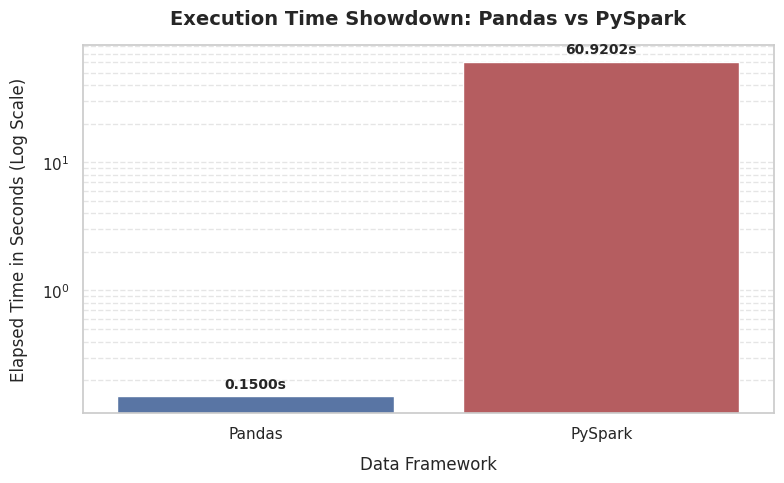

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the missing comparison DataFrame using the benchmarked times
comparison_df = pd.DataFrame({
    "Framework": ["Pandas", "PySpark"],
    "Elapsed seconds": [pandas_seconds, spark_seconds]
})

# 1. Initialize the plotting canvas
plt.figure(figsize=(8, 5))

# 2. Generate the bar plot with a clean, professional color palette
ax = sns.barplot(
    data=comparison_df,
    x="Framework",
    y="Elapsed seconds",
    palette=["#4C72B0", "#C44E52"]
)

# 3. Use a log scale so BOTH bars are perfectly visible
plt.yscale('log')

# 4. ADD VALUE LABELS: Print the exact timing text on top of each bar
for container in ax.containers:
    labels = [f'{v.get_height():.4f}s' if v.get_height() > 0 else '' for v in container]
    ax.bar_label(container, labels=labels, label_type='edge', padding=4, fontsize=10, weight='bold')

# 5. Adding thorough visual explanations and grid lines
plt.title("Execution Time Showdown: Pandas vs PySpark", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Data Framework", fontsize=12, labelpad=10)
plt.ylabel("Elapsed Time in Seconds (Log Scale)", fontsize=12, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5, which="both")

# Adjust layout margins so labels don't get chopped off
plt.tight_layout()

# 6. Save the new explanatory chart directly to your permanent Drive folder
plt.savefig(
    PLOT_DIR / "07_pandas_vs_pyspark_explanatory.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [ ]:
with pd.HDFStore(str(H5_PATH), mode="a") as store:
    store.put(
        "pandas_spark_comparison",
        comparison_df,
        format="fixed"
    )

print("Spark comparison added to:", H5_PATH)

spark.stop()
print("Spark session stopped.")

Spark comparison added to: /content/drive/MyDrive/Energy_ML_Project/results/energy_ml_results.h5
Spark session stopped.


### Fast Presentation Mode (Skip Re-training)
Use the cell below to instantly load and display your final results directly from your Google Drive without rerunning any machine learning models or PySpark jobs.

--- 1. LOADING EXPERIMENT METADATA ---


,setting,value
0,best_model,Random Forest
1,target,Global_active_power
2,prediction_horizon,1 minute ahead
3,low_threshold_kw,0.336
4,high_threshold_kw,1.402
5,train_fraction,0.7
6,validation_fraction,0.15
7,test_fraction,0.15
8,random_state,42
9,training_rows,730721



--- 2. FINAL TEST PERFORMANCE ---


,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Model,Training Time (seconds)
0,0.951751,0.952979,0.952366,0.952979,0.952668,Random Forest,114.477570
1,0.951425,0.952319,0.952208,0.952319,0.952263,HistGradientBoosting,27.825425
2,0.949229,0.950218,0.950169,0.950218,0.950192,Decision Tree,12.124210
3,0.942599,0.942786,0.943690,0.942786,0.943230,Extra Trees,38.677523
4,0.902206,0.911308,0.900696,0.911308,0.903802,Logistic Regression,45.953016



--- 3. VISUALIZING KEY PERFORMANCE GRAPHICS ---


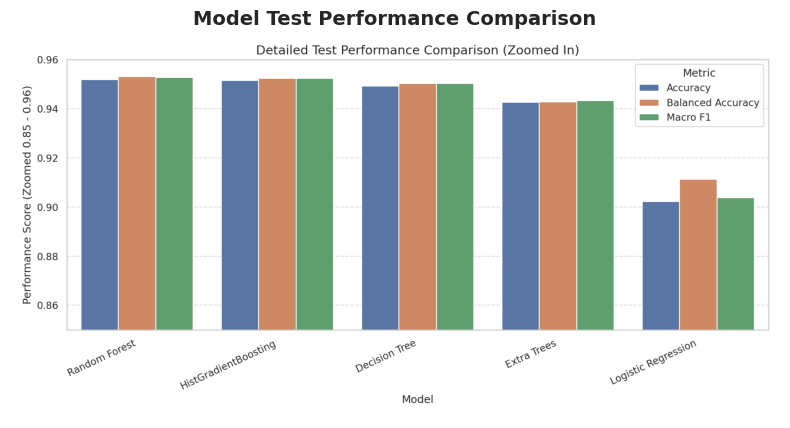

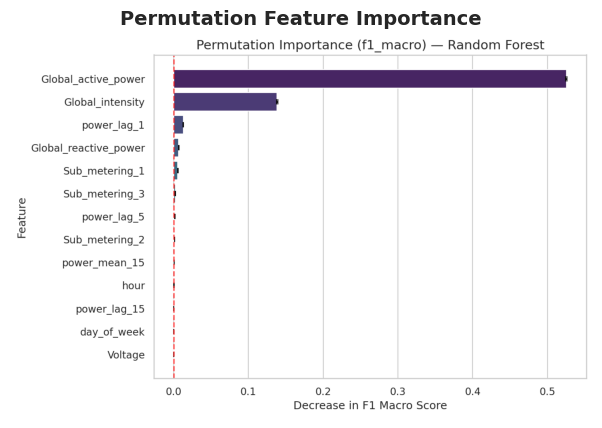

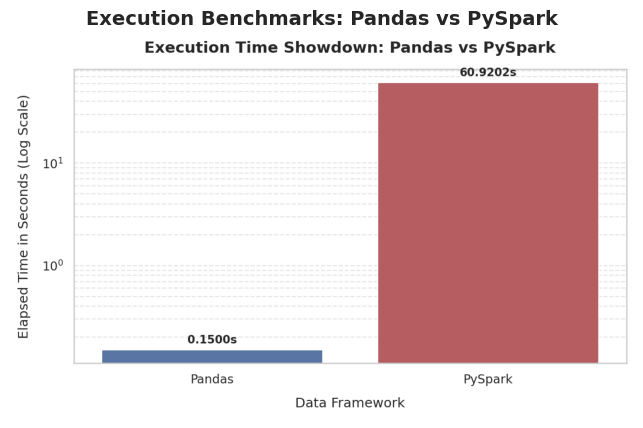

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

# Define the paths
PROJECT_DIR = Path("/content/drive/MyDrive/Energy_ML_Project")
RESULT_DIR = PROJECT_DIR / "results"
PLOT_DIR = RESULT_DIR / "plots"
H5_PATH = RESULT_DIR / "energy_ml_results.h5"

print("--- 1. LOADING EXPERIMENT METADATA ---")
if H5_PATH.exists():
    with pd.HDFStore(str(H5_PATH), mode="r") as store:
        display(store["experiment_metadata"])
        print("\n--- 2. FINAL TEST PERFORMANCE ---")
        display(store["test_metrics"])
else:
    print("Results file not found. Please make sure Google Drive is mounted.")

# Function to safely display saved figures
def show_plot(plot_path, title):
    if plot_path.exists():
        plt.figure(figsize=(10, 5))
        img = mpimg.imread(plot_path)
        plt.imshow(img)
        plt.axis('off')
        plt.title(title, fontsize=14, fontweight='bold')
        plt.show()
    else:
        print(f"Plot not found: {plot_path.name}")

print("\n--- 3. VISUALIZING KEY PERFORMANCE GRAPHICS ---")
show_plot(PLOT_DIR / "09_model_test_zoomed_comparison.png", "Model Test Performance Comparison")
show_plot(PLOT_DIR / "05_permutation_importance.png", "Permutation Feature Importance")
show_plot(PLOT_DIR / "07_pandas_vs_pyspark_explanatory.png", "Execution Benchmarks: Pandas vs PySpark")

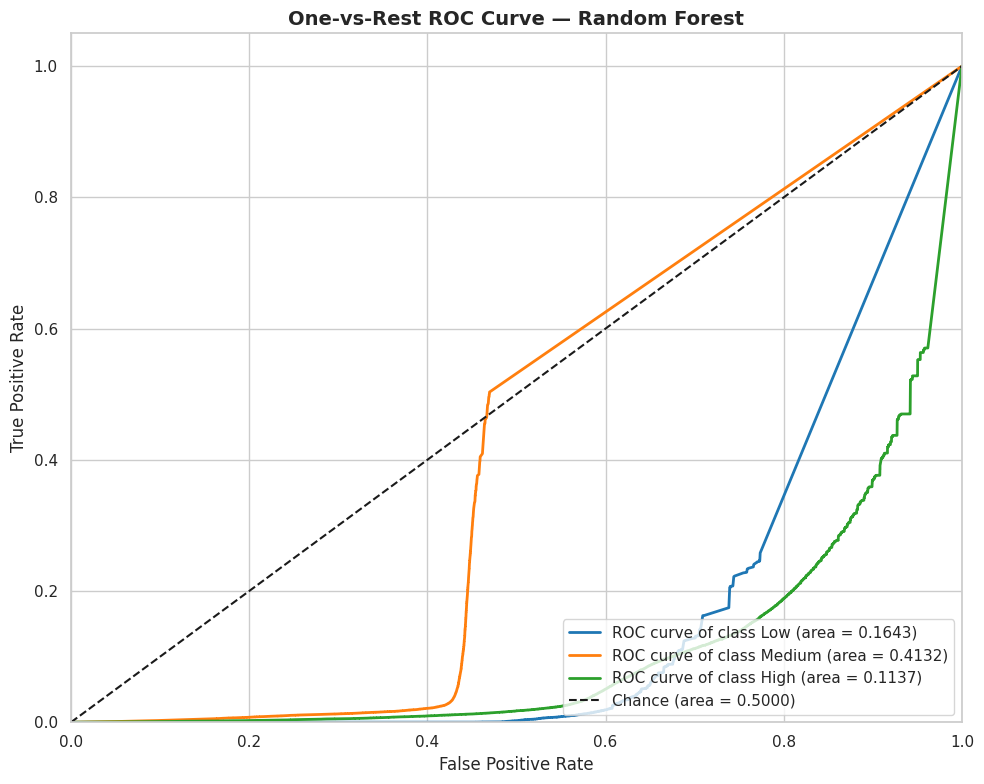

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Binarize the output for multi-class ROC calculation
# CLASS_NAMES = ['Low', 'Medium', 'High']
y_test_bin = label_binarize(y_test, classes=CLASS_NAMES)
n_classes = y_test_bin.shape[1]

plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

# We will plot the multi-class ROC curve for our best model (Random Forest)
rf_model = fitted_models["Random Forest"]
y_score = rf_model.predict_proba(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(
        fpr[i],
        tpr[i],
        color=colors[i],
        lw=2,
        label=f"ROC curve of class {CLASS_NAMES[i]} (area = {roc_auc[i]:.4f})"
    )

# Plot the diagonal baseline
plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Chance (area = 0.5000)")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("One-vs-Rest ROC Curve — Random Forest", fontsize=14, fontweight="bold")
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()

# Save the plot
plt.savefig(PLOT_DIR / "11_random_forest_roc_curve.png", dpi=150)
plt.show()


### Option A: The Fast Python Frontend (Streamlit)
Streamlit is the most popular framework for data scientists to build frontend applications instantly using pure Python. Here is the code to create a modern web dashboard with input sliders, interactive charts, and model predictions.

In [ ]:
with open("app.py", "w") as f:
    f.write('''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(page_title="Energy Consumption Predictor", layout="wide")

st.title("⚡ Household Energy Consumption Predictor")
st.markdown("Predict future energy demand levels (Low, Medium, High) using your trained Random Forest Classifier.")

# Sidebar inputs for the features
st.sidebar.header("🔌 Real-Time Measurements Input")

global_active_power = st.sidebar.slider("Global Active Power (kW)", 0.0, 12.0, 1.1)
global_intensity = st.sidebar.slider("Global Intensity (Amps)", 0.0, 55.0, 4.8)
voltage = st.sidebar.slider("Voltage (V)", 220.0, 255.0, 240.0)
global_reactive_power = st.sidebar.slider("Global Reactive Power (kW)", 0.0, 1.5, 0.1)
sub_1 = st.sidebar.slider("Kitchen (Sub 1) (Wh)", 0.0, 40.0, 1.0)
sub_2 = st.sidebar.slider("Laundry / AC (Sub 2) (Wh)", 0.0, 40.0, 1.5)
sub_3 = st.sidebar.slider("Water Heater (Sub 3) (Wh)", 0.0, 40.0, 6.0)

hour = st.sidebar.slider("Hour of Day", 0, 23, 12)
day_of_week = st.sidebar.selectbox("Day of Week", [0, 1, 2, 3, 4, 5, 6], format_func=lambda x: ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"][x])

# Lags (estimating simple historical patterns for preview demo)
st.sidebar.header("⏳ Historical Lags")
power_lag_1 = st.sidebar.slider("Power Lag 1 min ago (kW)", 0.0, 12.0, global_active_power)
power_lag_5 = st.sidebar.slider("Power Lag 5 mins ago (kW)", 0.0, 12.0, global_active_power)
power_lag_15 = st.sidebar.slider("Power Lag 15 mins ago (kW)", 0.0, 12.0, global_active_power)
power_mean_15 = (power_lag_1 + power_lag_5 + power_lag_15) / 3.0

# Predict button
if st.button("🎯 Predict Future Demand Level"):
    try:
        # Load the model
        model_path = "/content/drive/MyDrive/Energy_ML_Project/models/random_forest.joblib"
        model = joblib.load(model_path)

        # Prepare feature vector matching exactly the 13 training features
        features = pd.DataFrame([[
            global_active_power, global_reactive_power, voltage, global_intensity,
            sub_1, sub_2, sub_3,
            power_lag_1, power_lag_5, power_lag_15, power_mean_15,
            hour, day_of_week
        ]], columns=[
            "Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity",
            "Sub_metering_1", "Sub_metering_2", "Sub_metering_3",
            "power_lag_1", "power_lag_5", "power_lag_15", "power_mean_15",
            "hour", "day_of_week"
        ])

        prediction = model.predict(features)[0]
        probabilities = model.predict_proba(features)[0]

        # Display result styled
        st.subheader("🔮 Prediction Result")
        col1, col2 = st.columns(2)

        with col1:
            if prediction == "High":
                st.error(f"🚨 Predicted Demand Level: **{prediction}**")
            elif prediction == "Medium":
                st.warning(f"⚠️ Predicted Demand Level: **{prediction}**")
            else:
                st.success(f"✅ Predicted Demand Level: **{prediction}**")

        with col2:
            prob_df = pd.DataFrame({
                'Category': model.classes_,
                'Probability (%)': np.round(probabilities * 100, 2)
            })
            st.write(prob_df)

    except Exception as e:
        st.error(f"Could not load model or predict: {e}. Please ensure model path is correct!")
''')

### Option B: REST API Backend (FastAPI) + HTML/JS Frontend
If you want to build a completely custom web page using **HTML/CSS/JS** or React, you need to expose your model via a backend framework like FastAPI. This creates an endpoint (`/predict`) that your frontend calls.

In [ ]:
with open("api.py", "w") as f:
    f.write('''
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import pandas as pd
import uvicorn

app = FastAPI(title="Energy Prediction API")

# Load the model
MODEL_PATH = "/content/drive/MyDrive/Energy_ML_Project/models/random_forest.joblib"
model = joblib.load(MODEL_PATH)

class PredictionInput(BaseModel):
    Global_active_power: float
    Global_reactive_power: float
    Voltage: float
    Global_intensity: float
    Sub_metering_1: float
    Sub_metering_2: float
    Sub_metering_3: float
    power_lag_1: float
    power_lag_5: float
    power_lag_15: float
    power_mean_15: float
    hour: int
    day_of_week: int

@app.post("/predict")
def predict(data: PredictionInput):
    # Transform JSON input to DataFrame
    df_input = pd.DataFrame([data.dict()])

    # Predict
    prediction = model.predict(df_input)[0]
    probabilities = model.predict_proba(df_input)[0].tolist()

    return {
        "prediction": prediction,
        "probabilities": dict(zip(model.classes_, probabilities))
    }

if __name__ == "__main__":
    uvicorn.run(app, host="0.0.0.0", port=8000)
''')

### Next Steps to Launch the Frontend on Your Computer:
1. **Download the model:** Save `random_forest.joblib` from Google Drive to your local machine.
2. **Setup your environment:** In your computer's terminal, run:
   ```bash
   pip install streamlit pandas numpy scikit-learn joblib matplotlib seaborn
   ```
3. **Run your App:** Navigate to your local project folder and run:
   ```bash
   streamlit run app.py
   ```